# Basic Sentiment Analysis on IMDB Reviews

**Aim:** classify IMDB movie reviews as positive or negative using (a) an Embedding + GlobalAveragePooling baseline and (b) an Embedding + SimpleRNN model, built with TensorFlow/Keras.

All functions live in `sentiment_rnn.py`; this notebook runs them step by step.

In [1]:
import numpy as np
from IPython.display import Image, Markdown, display
from tensorflow import keras
import sentiment_rnn as S

print('Vocab size:', S.VOCAB_SIZE, '| Max length:', S.MAX_LEN, '| Embedding dim:', S.EMBED_DIM)

Vocab size: 10000 | Max length: 200 | Embedding dim: 32


## 1. Load and preprocess the data

`keras.datasets.imdb` gives 25,000 training and 25,000 test reviews, already tokenised into word indices. We keep the 10,000 most frequent words and pad/truncate every review to 200 tokens.

In [2]:
data = S.load_data()
(x_train, y_train), (x_test, y_test) = data
print('Train:', x_train.shape, ' Test:', x_test.shape)
print('Class balance (train, fraction positive):', y_train.mean())

Train: (25000, 200)  Test: (25000, 200)
Class balance (train, fraction positive): 0.5


Decoding one review back to words (indices are offset by 3: 0 = padding, 1 = start, 2 = unknown):

In [3]:
index_to_word = {i + 3: w for w, i in keras.datasets.imdb.get_word_index().items()}
words = [index_to_word.get(i, '?') for i in x_train[0] if i > 2]
print('Label:', 'positive' if y_train[0] else 'negative')
print(' '.join(words))

Label: positive
and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you think the whole story was so lovely because it was true and was someone's life after all that was shared with us all


## 2. Model (a): Embedding + GlobalAveragePooling

Each word gets a learned 32-d vector; the vectors are averaged over the review (word order is ignored), then passed through a small dense classifier.

Model: "embedding_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,545 (1.22 MB)

 Trainable params: 320,545 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (14 outputs left out)

157/157 - 0s - 2ms/step - accuracy: 0.9344 - loss: 0.1792 - val_accuracy: 0.8836 - val_loss: 0.2890


Epoch 9/10


157/157 - 0s - 3ms/step - accuracy: 0.9396 - loss: 0.1650 - val_accuracy: 0.8822 - val_loss: 0.2923


embedding_gap: test loss=0.2953  test accuracy=0.8778
saved results/embedding_gap.png


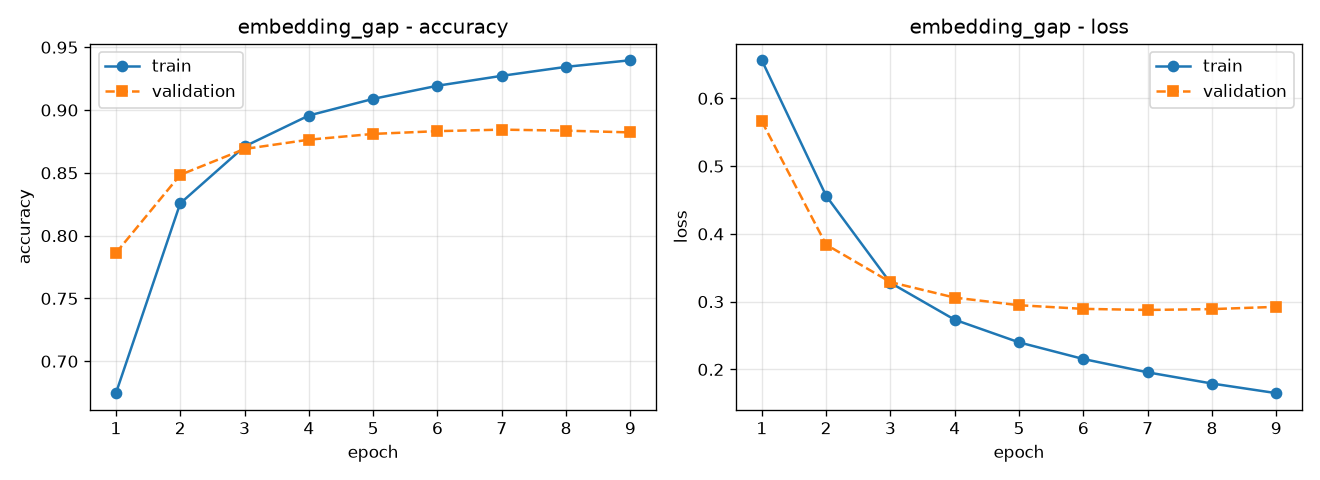

In [4]:
baseline = S.build_baseline()
hist_a, loss_a, acc_a = S.train_and_evaluate(baseline, data, epochs=10)
S.plot_history(hist_a, baseline.name)
display(Image(f'results/{baseline.name}.png'))

## 3. Model (b): Embedding + SimpleRNN

The SimpleRNN reads the review one word at a time and keeps a 32-unit hidden state; the final state is classified by a sigmoid unit.

Model: "embedding_simplernn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,113 (1.23 MB)

 Trainable params: 322,113 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


... (6 outputs left out)

157/157 - 3s - 18ms/step - accuracy: 0.9372 - loss: 0.1753 - val_accuracy: 0.8488 - val_loss: 0.4055


Epoch 5/5


157/157 - 3s - 18ms/step - accuracy: 0.9648 - loss: 0.1124 - val_accuracy: 0.8238 - val_loss: 0.4719


embedding_simplernn: test loss=0.3895  test accuracy=0.8386
saved results/embedding_simplernn.png


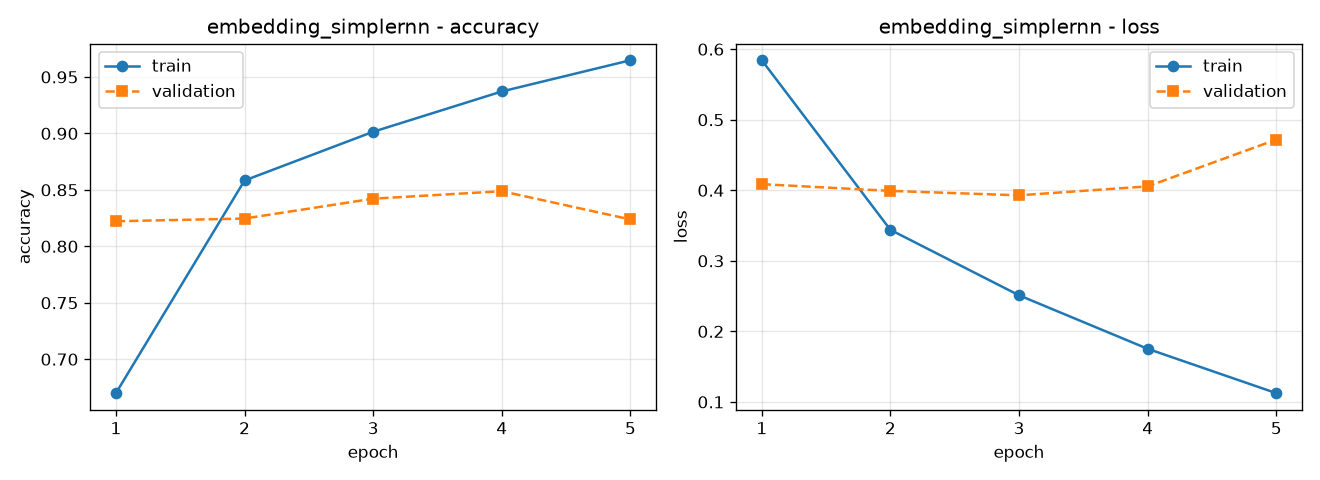

In [5]:
rnn = S.build_rnn()
hist_b, loss_b, acc_b = S.train_and_evaluate(rnn, data, epochs=5)
S.plot_history(hist_b, rnn.name)
display(Image(f'results/{rnn.name}.png'))

## 4. Results

In [6]:
table = '| Model | Params | Test loss | Test accuracy |\n|---|---|---|---|\n'
for m, l, a in [(baseline, loss_a, acc_a), (rnn, loss_b, acc_b)]:
    table += f'| {m.name} | {m.count_params():,} | {l:.4f} | {a:.2%} |\n'
display(Markdown(table))

| Model | Params | Test loss | Test accuracy |
|---|---|---|---|
| embedding_gap | 320,545 | 0.2953 | 87.78% |
| embedding_simplernn | 322,113 | 0.3895 | 83.86% |


## 5. Predicting custom reviews

In [7]:
for text in S.SAMPLES + ['One of the best films I have seen this year.']:
    print(text)
    for m in (baseline, rnn):
        label, p = S.predict(m, text)
        print(f'   {m.name:22s} -> {label} ({p:.3f})')

This movie was absolutely wonderful, the acting was brilliant and I loved the story.
   embedding_gap          -> positive (0.821)


   embedding_simplernn    -> positive (0.870)
A total waste of time. The plot was boring and the acting was terrible.
   embedding_gap          -> negative (0.027)
   embedding_simplernn    -> negative (0.007)
It had a few good moments but overall I was disappointed.


   embedding_gap          -> positive (0.521)
   embedding_simplernn    -> negative (0.176)
One of the best films I have seen this year.
   embedding_gap          -> positive (0.683)
   embedding_simplernn    -> negative (0.231)


## 6. Conclusion

- The Embedding + GlobalAveragePooling baseline reached **87.8%** test accuracy, beating the SimpleRNN (**83.9%**) while training ~10x faster per epoch.
- Sentiment in movie reviews is carried mostly by individual words ("brilliant", "waste"), which an order-free average captures well.
- The SimpleRNN overfits quickly (validation loss rises after 2–3 epochs; early stopping restores the best weights) and struggles with 200-step sequences because of vanishing gradients. LSTM/GRU layers are the usual next step.
- On custom text, both models handle clearly positive/negative reviews; short or mixed reviews ("good moments but … disappointed") are where they disagree and make mistakes.